In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv('online_retail_II.csv', encoding='ISO-8859-1')

# --- Initial Inspection ---

# See the first 5 rows
print("First 5 rows of the data:")
print(df.head())

# Get a summary of data types and non-null values
print("\nData Info:")
df.info()

# See the number of rows and columns
print(f"\nDataset shape: {df.shape}")

First 5 rows of the data:
  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

           InvoiceDate  Price  Customer ID         Country  
0  2009-12-01 07:45:00   6.95      13085.0  United Kingdom  
1  2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
2  2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
3  2009-12-01 07:45:00   2.10      13085.0  United Kingdom  
4  2009-12-01 07:45:00   1.25      13085.0  United Kingdom  

Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       -

In [2]:
# --- Data Cleaning ---

# Check for missing values
print("\nMissing values per column:")
print(df.isnull().sum())


Missing values per column:
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64


In [3]:
# Drop rows where CustomerID is missing
df.dropna(subset=['Customer ID'], inplace=True)

In [4]:
# # Remove returns (where Quantity is negative)
# df = df[df['Quantity'] > 0]

In [5]:
# Convert Customer ID to integer type
df['Customer ID'] = df['Customer ID'].astype(int)

In [6]:
# Verify the cleaning
print("\nShape after cleaning:", df.shape)
print("\nMissing values after cleaning:")
print(df.isnull().sum())


Shape after cleaning: (824364, 8)

Missing values after cleaning:
Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64


In [7]:
# Create TotalPrice column
df['TotalPrice'] = df['Quantity'] * df['Price']

# Get summary stats rounded to 2 decimals
summary = df[['Quantity', 'Price', 'TotalPrice']].describe().round(2)

# Style the table for a clean aesthetic
styled_summary = (
    summary.style
    .set_caption("📊 Summary Statistics")
    .set_table_styles([
        {"selector": "caption",
         "props": [("caption-side", "top"), ("font-size", "16px"), ("font-weight", "bold"), ("text-align", "center"), ("color", "#2F4F4F"), ("padding", "10px 0")]},
        {"selector": "thead th",
         "props": [("background-color", "#2F4F4F"), ("color", "white"), ("font-size", "14px"), ("padding", "6px 10px")]},
        {"selector": "tbody td",
         "props": [("text-align", "right"), ("font-size", "13px"), ("padding", "6px 10px")]},
        {"selector": "tbody tr:nth-child(even)",
         "props": [("background-color", "#f9f9f9")]},
        {"selector": "tbody tr:hover",
         "props": [("background-color", "#e6f2ff")]}
    ])
    .format(precision=2)
)

styled_summary


,Quantity,Price,TotalPrice
count,824364.00,824364.00,824364.00
mean,12.41,3.68,20.20
std,188.98,70.24,308.69
min,-80995.00,0.00,-168469.60
25%,2.00,1.25,4.25
50%,5.00,1.95,11.25
75%,12.00,3.75,19.50
max,80995.00,38970.00,168469.60


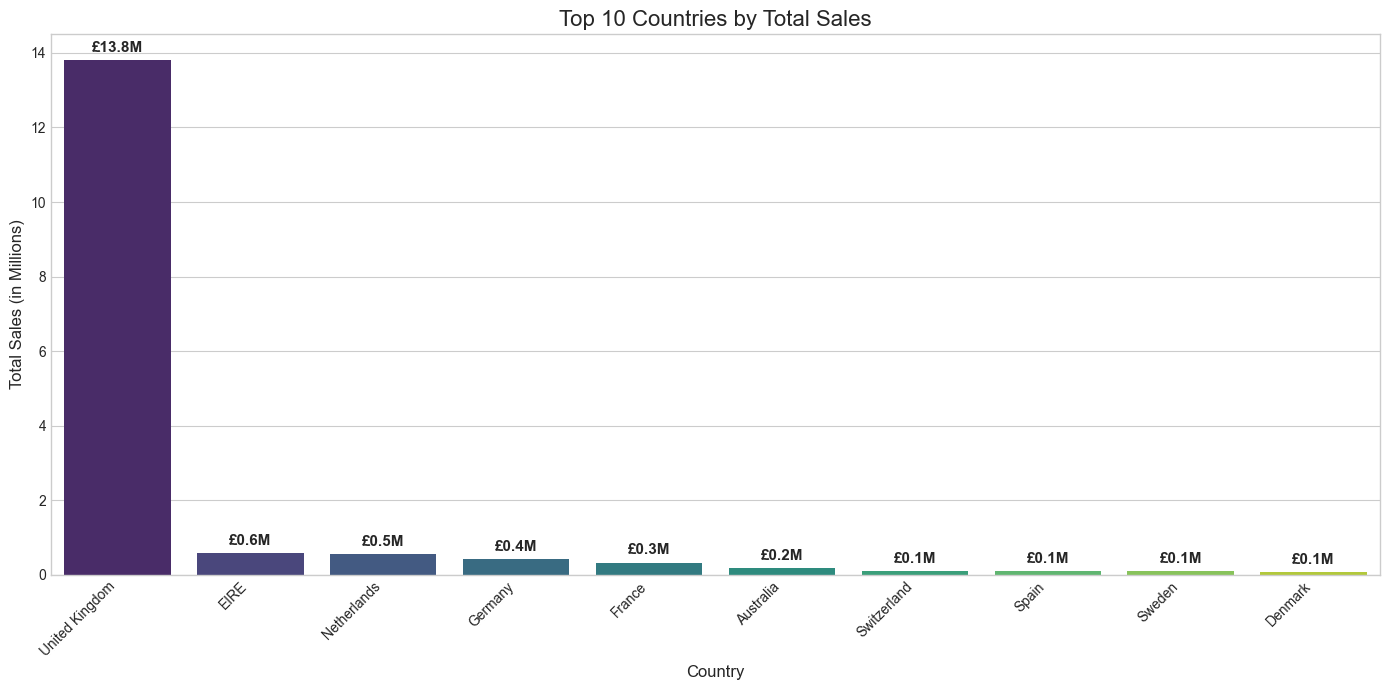

C:\Users\satya\AppData\Local\Temp\ipykernel_16184\3334497562.py:69: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_sales = df_time['TotalPrice'].resample('M').sum()


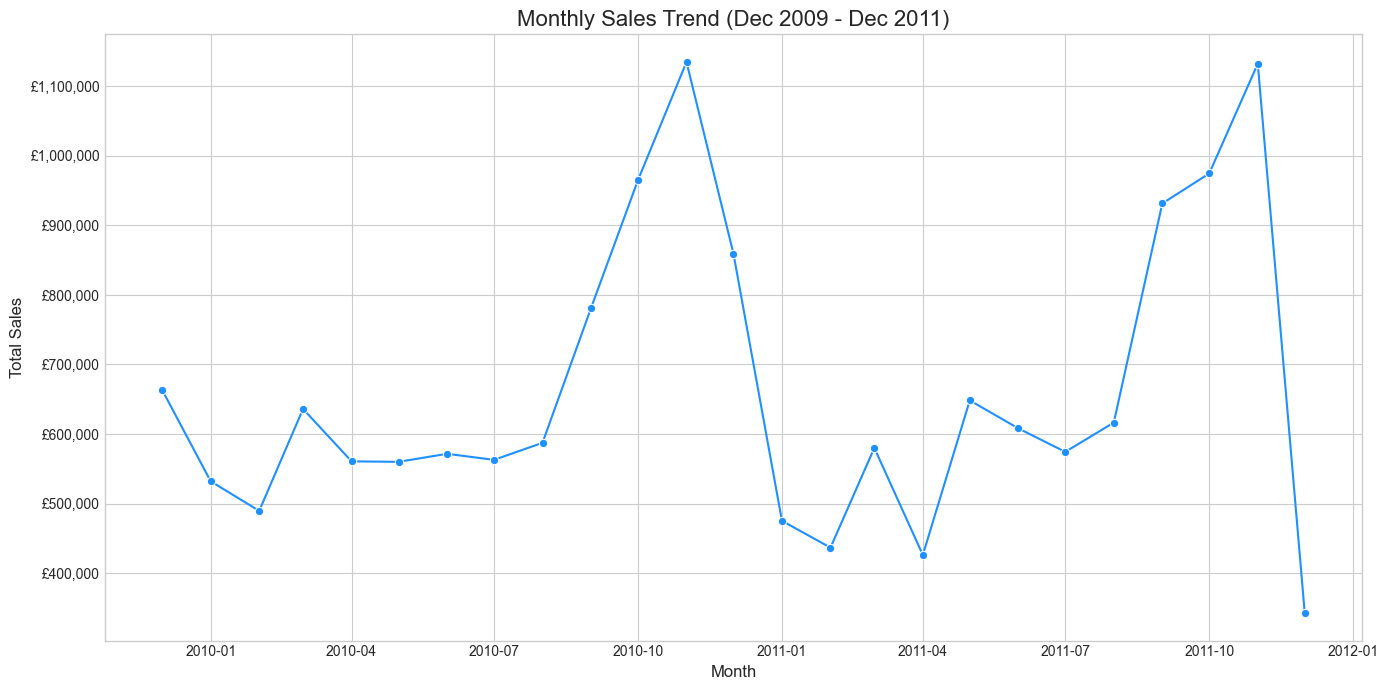

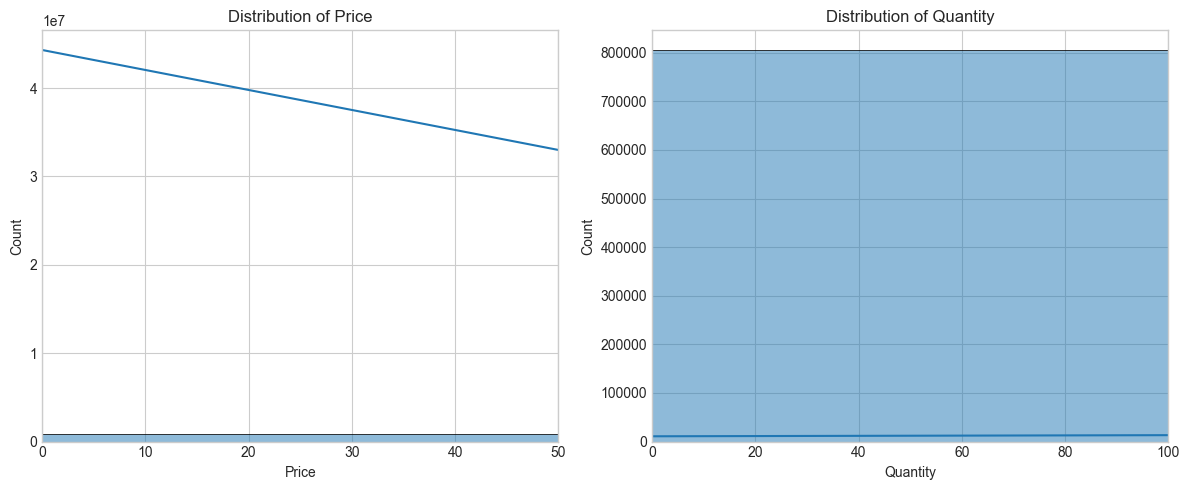

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# Assume 'df' is your cleaned DataFrame from the previous steps
# df['TotalPrice'] = df['Quantity'] * df['Price']

# --- 1. Improved Bar Chart with Data Labels ---
plt.style.use('seaborn-v0_8-whitegrid')
plt.figure(figsize=(14, 7))

# Calculate top 10 countries
top_countries = (
    df.groupby('Country')['TotalPrice']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

# Convert to millions for consistent labeling
top_countries_mil = top_countries / 1_000_000

# Bar plot
ax = sns.barplot(
    x=top_countries_mil.index,
    y=top_countries_mil.values,
    palette='viridis',
    hue=top_countries_mil.index,
    legend=False
)

# Add value labels on bars
for p in ax.patches:
    value_label = f'£{p.get_height():.1f}M'
    ax.annotate(
        value_label,
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='center',
        xytext=(0, 9),
        textcoords='offset points',
        fontsize=11,
        fontweight='bold'
    )

# Titles and labels
plt.title('Top 10 Countries by Total Sales', fontsize=16)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Total Sales (in Millions)', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Disable scientific notation on y-axis
ax.ticklabel_format(style='plain', axis='y')

plt.tight_layout()
plt.show()



# --- 2. NEW: Line Chart for Monthly Sales Trend ---

# First, ensure 'InvoiceDate' is in datetime format
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Create a temporary dataframe with InvoiceDate as the index
df_time = df.set_index('InvoiceDate')

# Resample the data by month ('M') and sum the TotalPrice for each month
monthly_sales = df_time['TotalPrice'].resample('M').sum()

# Create the line plot
plt.figure(figsize=(14, 7))

# Shift the index back by one month to align with actual month start
monthly_sales.index = monthly_sales.index - pd.offsets.MonthBegin(1)
sns.lineplot(x=monthly_sales.index, y=monthly_sales.values, marker='o', color='dodgerblue', linestyle='-')

# Add a title and labels
plt.title('Monthly Sales Trend (Dec 2009 - Dec 2011)', fontsize=16)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Total Sales', fontsize=12)

# Format the y-axis to show currency in a readable way
def currency_formatter(x, pos):
    return f'£{x:,.0f}'
plt.gca().yaxis.set_major_formatter(FuncFormatter(currency_formatter))

plt.grid(True)
plt.tight_layout()
plt.show()


# --- 3. Distribution Plots (Unchanged) ---

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df['Price'], bins=50, kde=True)
plt.title('Distribution of Price')
plt.xlim(0, 50)

plt.subplot(1, 2, 2)
sns.histplot(df['Quantity'], bins=50, kde=True)
plt.title('Distribution of Quantity')
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

In [9]:
# # Create a new dataframe containing only UK customers
# df_uk = df[df['Country'] == 'United Kingdom'].copy()

# # --- Calculate Returns BEFORE cleaning ---
# returns_data = df_uk[df_uk['Quantity'] < 0].copy()
# returns_data['ReturnedItems'] = abs(returns_data['Quantity'])
# customer_returns = returns_data.groupby('Customer ID')['ReturnedItems'].sum().reset_index()

# print(f"Original data shape: {df.shape}")
# print(f"Shape after filtering for UK: {df_uk.shape}")

In [10]:
# --- 1. Filter for UK Customers (This is your new Cell 4) ---
# We do this on the 'df' that still has returns in it.
df_uk = df[df['Country'] == 'United Kingdom'].copy()
print(f"Shape after filtering for UK: {df_uk.shape}")

df_uk_before_cleaning = df_uk.copy() # Save snapshot before cleaning

# --- 2. Calculate Returns (This is your new Cell 5) ---
# NOW we calculate returns from the df_uk dataframe
returns_data = df_uk[df_uk['Quantity'] < 0].copy()
returns_data['ReturnedItems'] = abs(returns_data['Quantity'])
customer_returns = returns_data.groupby('Customer ID')['ReturnedItems'].sum().reset_index()
print(f"Found {len(customer_returns)} customers with returns.")

# --- 3. Basic Cleaning (This is your new Cell 6) ---
# Now we can safely remove returns from df_uk for purchase analysis
df_uk = df_uk[df_uk['Quantity'] > 0]
df_uk['Customer ID'] = df_uk['Customer ID'].astype(int)
df_uk['TotalPrice'] = df_uk['Quantity'] * df_uk['Price']
print(f"Shape after removing returns: {df_uk.shape}")

Shape after filtering for UK: (741301, 9)
Found 2307 customers with returns.
Shape after removing returns: (725296, 9)


In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
import datetime as dt

# --- NOTE: WE SKIPPED THE IQR OUTLIER REMOVAL HERE ---

In [13]:
# Remove zero-priced items
df_exp = df_uk[df_uk['Price'] > 0]

In [14]:
# 4. Remove non-product descriptions
# --- List of exact, non-product descriptions to remove ---
# We will convert these to lowercase for matching
non_product_descriptions = {
    'postage', 
    'bank charges', 
    'discount', 
    'manual', 
    'carriage', 
    'samples',
    'packing charges',
    'dotcom postage',
    'next day carriage'
}

print("--- Detailed Non-Product Row Analysis ---")

# Create a boolean mask to identify the rows to remove
# We convert the 'Description' column to lowercase for a case-insensitive match
rows_to_remove_mask = df_exp['Description'].str.lower().isin(non_product_descriptions)

# Get the value counts of the descriptions that will be removed
description_counts = df_exp.loc[rows_to_remove_mask, 'Description'].str.lower().value_counts()

if description_counts.empty:
    print("No non-product descriptions found to remove.")
else:
    print("Found the following non-product descriptions to remove:")
    print(description_counts)
    print("-" * 35) # Separator line

# --- Remove the rows using the precise filter ---
# The '~' symbol means NOT, so we keep rows that are NOT in our set
original_rows = df_exp.shape[0]
df_exp = df_exp[~rows_to_remove_mask]

# --- Final Summary ---
print(f"Removed a total of {description_counts.sum()} non-product rows.")
print(f"Original shape: {original_rows} rows")
print(f"Shape after removal: {df_exp.shape[0]} rows")

--- Detailed Non-Product Row Analysis ---
Found the following non-product descriptions to remove:
Description
manual               622
next day carriage     79
carriage              59
postage               36
bank charges          29
dotcom postage        16
discount               5
Name: count, dtype: int64
-----------------------------------
Removed a total of 846 non-product rows.
Original shape: 725250 rows
Shape after removal: 724404 rows


In [15]:
import datetime as dt
import numpy as np

# --- Feature Engineering ---
snapshot_date_exp = df_exp['InvoiceDate'].max() + dt.timedelta(days=1)

# Group by customer to create initial features
rfm_data_exp = df_exp.groupby(['Customer ID']).agg({
    'InvoiceDate': lambda x: (snapshot_date_exp - x.max()).days,
    'Invoice': 'nunique',
    'TotalPrice': 'sum'
})
rfm_data_exp.rename(columns={'InvoiceDate': 'Recency', 'Invoice': 'Frequency', 'TotalPrice': 'Monetary'}, inplace=True)

# --- Add other engineered features ---
# (Pasting the rest of the feature code here for completeness)
rfm_data_exp['AverageOrderValue'] = rfm_data_exp['Monetary'] / rfm_data_exp['Frequency']
customer_lifetime = df_exp.groupby('Customer ID')['InvoiceDate'].agg(['min', 'max'])
rfm_data_exp['CustomerLifetime'] = (customer_lifetime['max'] - customer_lifetime['min']).dt.days
product_counts = df_exp.groupby('Customer ID')['StockCode'].agg(['count', 'nunique'])
rfm_data_exp['TotalProducts'] = product_counts['count']
rfm_data_exp['UniqueProducts'] = product_counts['nunique']
rfm_data_exp['AvgBasketSize'] = rfm_data_exp['TotalProducts'] / rfm_data_exp['Frequency']
rfm_data_exp['DaysSinceFirstPurchase'] = (snapshot_date_exp - customer_lifetime['min']).dt.days
rfm_data_exp['AvgDaysBetweenPurchases'] = (rfm_data_exp['CustomerLifetime'] + 1) / rfm_data_exp['Frequency']
rfm_data_exp['ProductDiversity'] = rfm_data_exp['UniqueProducts'] / rfm_data_exp['TotalProducts']

# --- THIS IS THE FIX FOR THE CUSTOMER ID ISSUE ---
# Convert the Customer ID index to a column BEFORE merging
rfm_data_exp.reset_index(inplace=True)

# Merge the return data
rfm_data_exp = pd.merge(rfm_data_exp, customer_returns, on='Customer ID', how='left')
rfm_data_exp['ReturnedItems'] = rfm_data_exp['ReturnedItems'].fillna(0)

# Calculate ReturnRate
rfm_data_exp['ReturnRate'] = rfm_data_exp['ReturnedItems'] / (rfm_data_exp['ReturnedItems'] + rfm_data_exp['TotalProducts'])

# Set Customer ID back to be the index so it is NOT scaled
rfm_data_exp.set_index('Customer ID', inplace=True)

# Clean up final features
rfm_data_exp['ProductDiversity'] = rfm_data_exp['ProductDiversity'].fillna(0)
rfm_data_exp['ReturnRate'] = rfm_data_exp['ReturnRate'].fillna(0)
rfm_data_exp.drop(columns=['ReturnedItems'], inplace=True)

print("--- Final Engineered Features ---")
print(rfm_data_exp.head())
print(f"\nTotal features to be scaled: {len(rfm_data_exp.columns)}")

--- Final Engineered Features ---
             Recency  Frequency  Monetary  AverageOrderValue  \
Customer ID                                                    
12346            326         12  77556.46        6463.038333   
12608            405          1    415.79         415.790000   
12745            487          2    723.85         361.925000   
12746            541          1    254.55         254.550000   
12747              2         26   9276.54         356.790000   

             CustomerLifetime  TotalProducts  UniqueProducts  AvgBasketSize  \
Customer ID                                                                   
12346                     400             34              27       2.833333   
12608                       0             16              16      16.000000   
12745                      87             22              20      11.000000   
12746                       0             17              17      17.000000   
12747                     730            25

In [17]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# Handle skew by applying a log transformation
# We use log1p to handle potential zero values
log_transformed_data_exp = np.log1p(rfm_data_exp)

# Scale the data
scaler = StandardScaler()
scaled_data_exp = scaler.fit_transform(log_transformed_data_exp)

# Convert back to a DataFrame
scaled_df_exp = pd.DataFrame(scaled_data_exp, index=rfm_data_exp.index, columns=rfm_data_exp.columns)

print("\nScaled Data Head:")
print(scaled_df_exp.head())


Scaled Data Head:
              Recency  Frequency  Monetary  AverageOrderValue  \
Customer ID                                                     
12346        0.850549   1.248942  3.242590           4.515097   
12608        0.989130  -1.063691 -0.553163           0.629406   
12745        1.106943  -0.562734 -0.151245           0.433258   
12746        1.174154  -1.063691 -0.908441          -0.063934   
12747       -2.153858   2.151961  1.700360           0.413060   

             CustomerLifetime  TotalProducts  UniqueProducts  AvgBasketSize  \
Customer ID                                                                   
12346                0.732851      -0.323510       -0.348785      -1.837622   
12608               -1.500944      -0.850552       -0.758473      -0.001056   
12745                0.167644      -0.629936       -0.584981      -0.430527   
12746               -1.500944      -0.808836       -0.711544       0.069421   
12747                0.956624       1.134425       

In [18]:
# --- Generate the new summary statistics ---
print("Updated Summary Statistics (after removing zero-priced items):")
print(df_exp[['Quantity', 'Price', 'TotalPrice']].describe())

Updated Summary Statistics (after removing zero-priced items):
            Quantity          Price     TotalPrice
count  724404.000000  724404.000000  724404.000000
mean       12.003204       2.931006      20.186697
std       140.850412       4.421866     232.771457
min         1.000000       0.001000       0.001000
25%         2.000000       1.250000       4.200000
50%         4.000000       1.950000      10.200000
75%        12.000000       3.750000      17.700000
max     80995.000000     649.500000  168469.600000


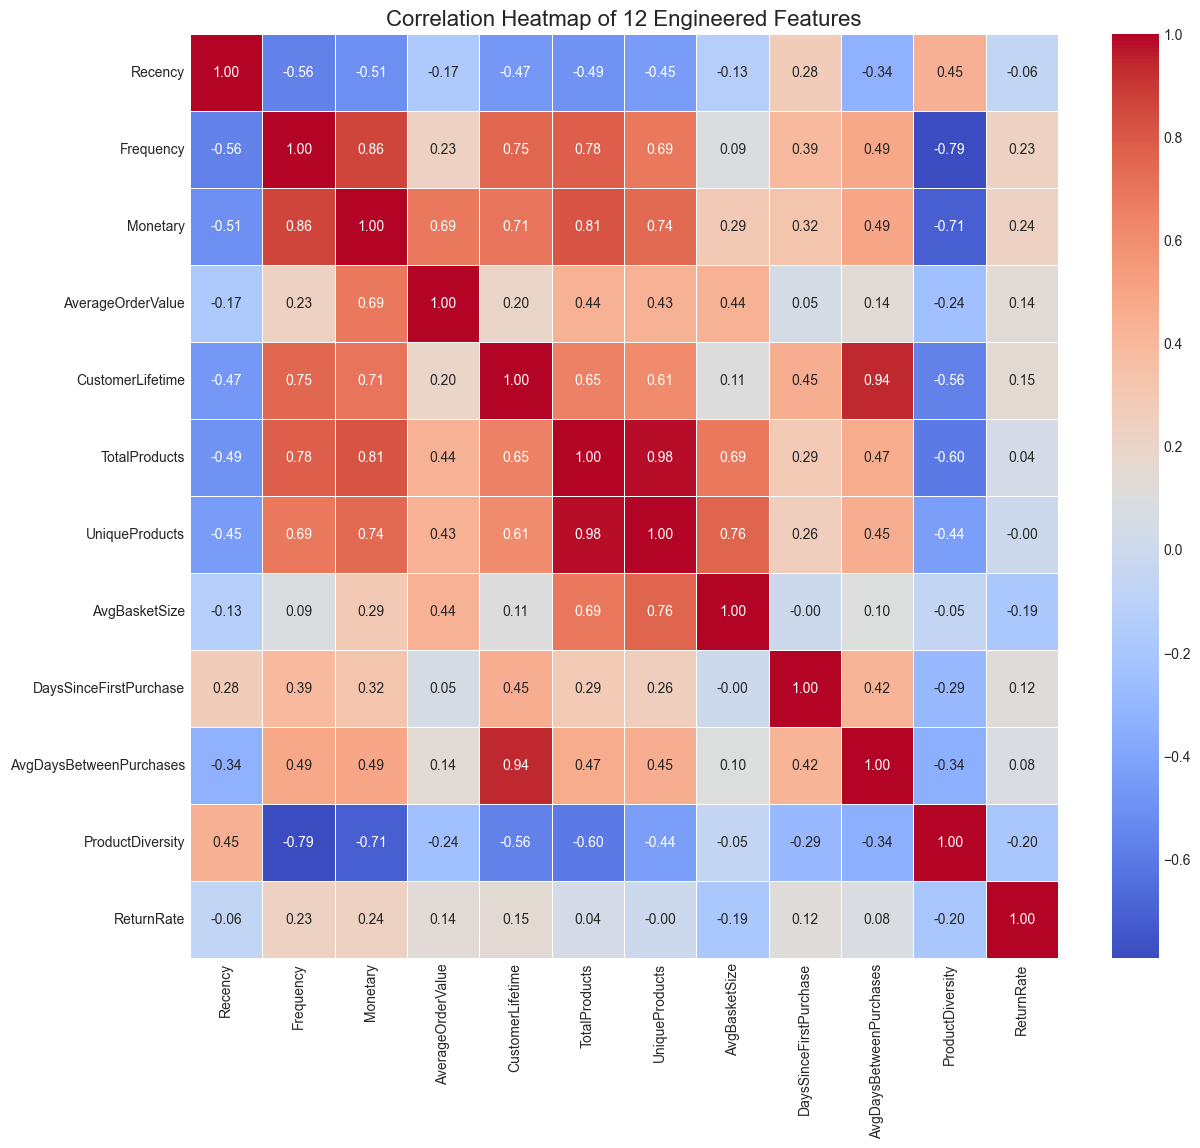

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

# 'scaled_df' is the final DataFrame from your scaling step
# Create a correlation matrix of the scaled data
corr_matrix_exp = scaled_df_exp.corr()

# Plot the heatmap
plt.figure(figsize=(14, 12))
sns.heatmap(corr_matrix_exp, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Heatmap of 12 Engineered Features', fontsize=16)
plt.show()

Running K-Means on data WITH OUTLIERS...


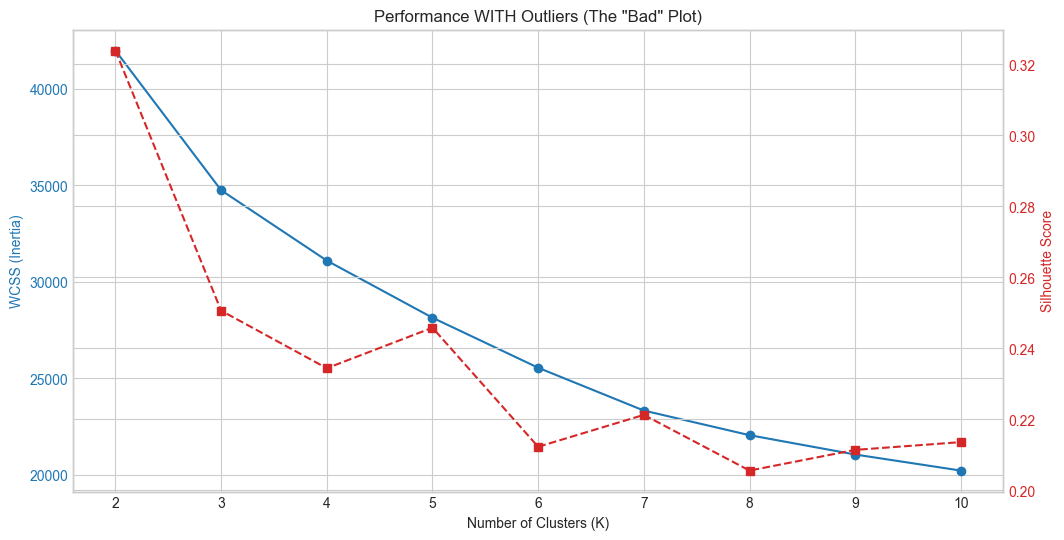

In [20]:
# --- 4. Run K-Means and Plot (The "Bad" Plot) ---
wcss = []
silhouette_scores = []
K_range = range(2, 11)

print("Running K-Means on data WITH OUTLIERS...")

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(scaled_df_exp)
    wcss.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(scaled_df_exp, kmeans.labels_))

# Plotting
fig, ax1 = plt.subplots(figsize=(12, 6))

color = 'tab:blue'
ax1.set_xlabel('Number of Clusters (K)')
ax1.set_ylabel('WCSS (Inertia)', color=color)
ax1.plot(K_range, wcss, marker='o', color=color, label='WCSS')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_title('Performance WITH Outliers (The "Bad" Plot)')

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Silhouette Score', color=color)
ax2.plot(K_range, silhouette_scores, marker='s', linestyle='--', color=color, label='Silhouette Score')
ax2.tick_params(axis='y', labelcolor=color)

plt.show()

In [22]:
selected_features = [
    'Recency',
    'Frequency',
    'Monetary',
    'CustomerLifetime',
    'ProductDiversity',
    'ReturnRate'
]


# Create the new dataframe with only the selected features
scaled_df_selected_exp = scaled_df_exp[selected_features]


Running K-Means on data WITH OUTLIERS...


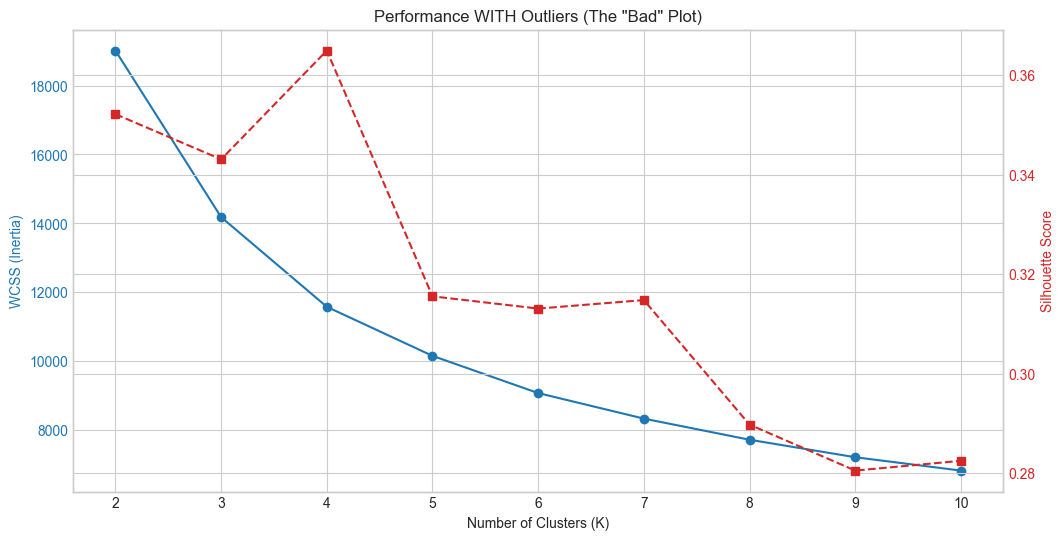

In [23]:
# --- 4. Run K-Means and Plot (The "Bad" Plot) ---
wcss = []
silhouette_scores = []
K_range = range(2, 11)

print("Running K-Means on data WITH OUTLIERS...")

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(scaled_df_selected_exp)
    wcss.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(scaled_df_selected_exp, kmeans.labels_))

# Plotting
fig, ax1 = plt.subplots(figsize=(12, 6))

color = 'tab:blue'
ax1.set_xlabel('Number of Clusters (K)')
ax1.set_ylabel('WCSS (Inertia)', color=color)
ax1.plot(K_range, wcss, marker='o', color=color, label='WCSS')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_title('Performance WITH Outliers (The "Bad" Plot)')

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Silhouette Score', color=color)
ax2.plot(K_range, silhouette_scores, marker='s', linestyle='--', color=color, label='Silhouette Score')
ax2.tick_params(axis='y', labelcolor=color)

plt.show()

In [11]:
# --- Main Data Cleaning Pipeline ---

# # 1. Remove returns from the main dataframe for purchase analysis
# df_uk = df_uk[df_uk['Quantity'] > 0]

# 2. Remove outliers from Quantity and TotalPrice
def remove_outliers(df, column_name):
    Q1 = df[column_name].quantile(0.25)
    Q3 = df[column_name].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return df[(df[column_name] >= lower_bound) & (df[column_name] <= upper_bound)]

df_uk = remove_outliers(df_uk, 'Quantity')
df_uk = remove_outliers(df_uk, 'TotalPrice')

# 3. Remove zero-priced items
df_uk = df_uk[df_uk['Price'] > 0]

print("Shape of data after all cleaning:", df_uk.shape)

Shape of data after all cleaning: (649880, 9)


In [12]:
# 4. Remove non-product descriptions
# --- List of exact, non-product descriptions to remove ---
# We will convert these to lowercase for matching
non_product_descriptions = {
    'postage', 
    'bank charges', 
    'discount', 
    'manual', 
    'carriage', 
    'samples',
    'packing charges',
    'dotcom postage',
    'next day carriage'
}

print("--- Detailed Non-Product Row Analysis ---")

# Create a boolean mask to identify the rows to remove
# We convert the 'Description' column to lowercase for a case-insensitive match
rows_to_remove_mask = df_uk['Description'].str.lower().isin(non_product_descriptions)

# Get the value counts of the descriptions that will be removed
description_counts = df_uk.loc[rows_to_remove_mask, 'Description'].str.lower().value_counts()

if description_counts.empty:
    print("No non-product descriptions found to remove.")
else:
    print("Found the following non-product descriptions to remove:")
    print(description_counts)
    print("-" * 35) # Separator line

# --- Remove the rows using the precise filter ---
# The '~' symbol means NOT, so we keep rows that are NOT in our set
original_rows = df_uk.shape[0]
df_uk = df_uk[~rows_to_remove_mask]

# --- Final Summary ---
print(f"Removed a total of {description_counts.sum()} non-product rows.")
print(f"Original shape: {original_rows} rows")
print(f"Shape after removal: {df_uk.shape[0]} rows")

--- Detailed Non-Product Row Analysis ---
Found the following non-product descriptions to remove:
Description
manual               502
next day carriage     79
bank charges          29
postage               28
dotcom postage         3
discount               2
carriage               1
Name: count, dtype: int64
-----------------------------------
Removed a total of 644 non-product rows.
Original shape: 649880 rows
Shape after removal: 649236 rows


In [13]:
import datetime as dt
import numpy as np

# --- Feature Engineering ---
snapshot_date = df_uk['InvoiceDate'].max() + dt.timedelta(days=1)

# Group by customer to create initial features
rfm_data = df_uk.groupby(['Customer ID']).agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'Invoice': 'nunique',
    'TotalPrice': 'sum'
})
rfm_data.rename(columns={'InvoiceDate': 'Recency', 'Invoice': 'Frequency', 'TotalPrice': 'Monetary'}, inplace=True)

# --- Add other engineered features ---
# (Pasting the rest of the feature code here for completeness)
rfm_data['AverageOrderValue'] = rfm_data['Monetary'] / rfm_data['Frequency']
customer_lifetime = df_uk.groupby('Customer ID')['InvoiceDate'].agg(['min', 'max'])
rfm_data['CustomerLifetime'] = (customer_lifetime['max'] - customer_lifetime['min']).dt.days
product_counts = df_uk.groupby('Customer ID')['StockCode'].agg(['count', 'nunique'])
rfm_data['TotalProducts'] = product_counts['count']
rfm_data['UniqueProducts'] = product_counts['nunique']
rfm_data['AvgBasketSize'] = rfm_data['TotalProducts'] / rfm_data['Frequency']
rfm_data['DaysSinceFirstPurchase'] = (snapshot_date - customer_lifetime['min']).dt.days
rfm_data['AvgDaysBetweenPurchases'] = (rfm_data['CustomerLifetime'] + 1) / rfm_data['Frequency']
rfm_data['ProductDiversity'] = rfm_data['UniqueProducts'] / rfm_data['TotalProducts']

# --- THIS IS THE FIX FOR THE CUSTOMER ID ISSUE ---
# Convert the Customer ID index to a column BEFORE merging
rfm_data.reset_index(inplace=True)

# Merge the return data
rfm_data = pd.merge(rfm_data, customer_returns, on='Customer ID', how='left')
rfm_data['ReturnedItems'] = rfm_data['ReturnedItems'].fillna(0)

# Calculate ReturnRate
rfm_data['ReturnRate'] = rfm_data['ReturnedItems'] / (rfm_data['ReturnedItems'] + rfm_data['TotalProducts'])

# Set Customer ID back to be the index so it is NOT scaled
rfm_data.set_index('Customer ID', inplace=True)

# Clean up final features
rfm_data['ProductDiversity'] = rfm_data['ProductDiversity'].fillna(0)
rfm_data['ReturnRate'] = rfm_data['ReturnRate'].fillna(0)
rfm_data.drop(columns=['ReturnedItems'], inplace=True)

print("--- Final Engineered Features ---")
print(rfm_data.head())
print(f"\nTotal features to be scaled: {len(rfm_data.columns)}")

--- Final Engineered Features ---
             Recency  Frequency  Monetary  AverageOrderValue  \
Customer ID                                                    
12346            529         10    327.86          32.786000   
12608            405          1     95.05          95.050000   
12745            487          2    364.33         182.165000   
12746            541          1    254.55         254.550000   
12747              2         26   3794.26         145.933077   

             CustomerLifetime  TotalProducts  UniqueProducts  AvgBasketSize  \
Customer ID                                                                   
12346                     196             32              26       3.200000   
12608                       0             11              11      11.000000   
12745                      87             17              16       8.500000   
12746                       0             17              17      17.000000   
12747                     730            19

In [14]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# Handle skew by applying a log transformation
# We use log1p to handle potential zero values
log_transformed_data = np.log1p(rfm_data)

# Scale the data
scaler = StandardScaler()
scaled_data = scaler.fit_transform(log_transformed_data)

# Convert back to a DataFrame
scaled_df = pd.DataFrame(scaled_data, index=rfm_data.index, columns=rfm_data.columns)

print("\nScaled Data Head:")
print(scaled_df.head())


Scaled Data Head:
              Recency  Frequency  Monetary  AverageOrderValue  \
Customer ID                                                     
12346        1.159706   1.121454 -0.434457          -2.255401   
12608        0.987759  -1.058772 -1.354459          -0.862987   
12745        1.106442  -0.540217 -0.355843          -0.002718   
12746        1.174151  -1.058772 -0.622988           0.441106   
12747       -2.178462   2.269844  1.393849          -0.296454   

             CustomerLifetime  TotalProducts  UniqueProducts  AvgBasketSize  \
Customer ID                                                                   
12346                0.479208      -0.325401       -0.368647      -1.709424   
12608               -1.482531      -1.073240       -1.047282      -0.405500   
12745                0.179977      -0.773495       -0.755798      -0.695660   
12746               -1.482531      -0.773495       -0.707964       0.098105   
12747                0.966082       0.984092       

In [16]:
# --- Generate the new summary statistics ---
print("Updated Summary Statistics (after removing zero-priced items):")
print(df_uk[['Quantity', 'Price', 'TotalPrice']].describe())

Updated Summary Statistics (after removing zero-priced items):
            Quantity          Price     TotalPrice
count  649236.000000  649236.000000  649236.000000
mean        6.185418       2.798762      10.824146
std         6.186087       2.691831       8.188560
min         1.000000       0.001000       0.001000
25%         2.000000       1.250000       3.750000
50%         4.000000       1.950000       9.900000
75%        10.000000       3.750000      15.900000
max        27.000000      35.950000      36.640000


In [17]:
df_uk.to_csv('output.csv', index=False)


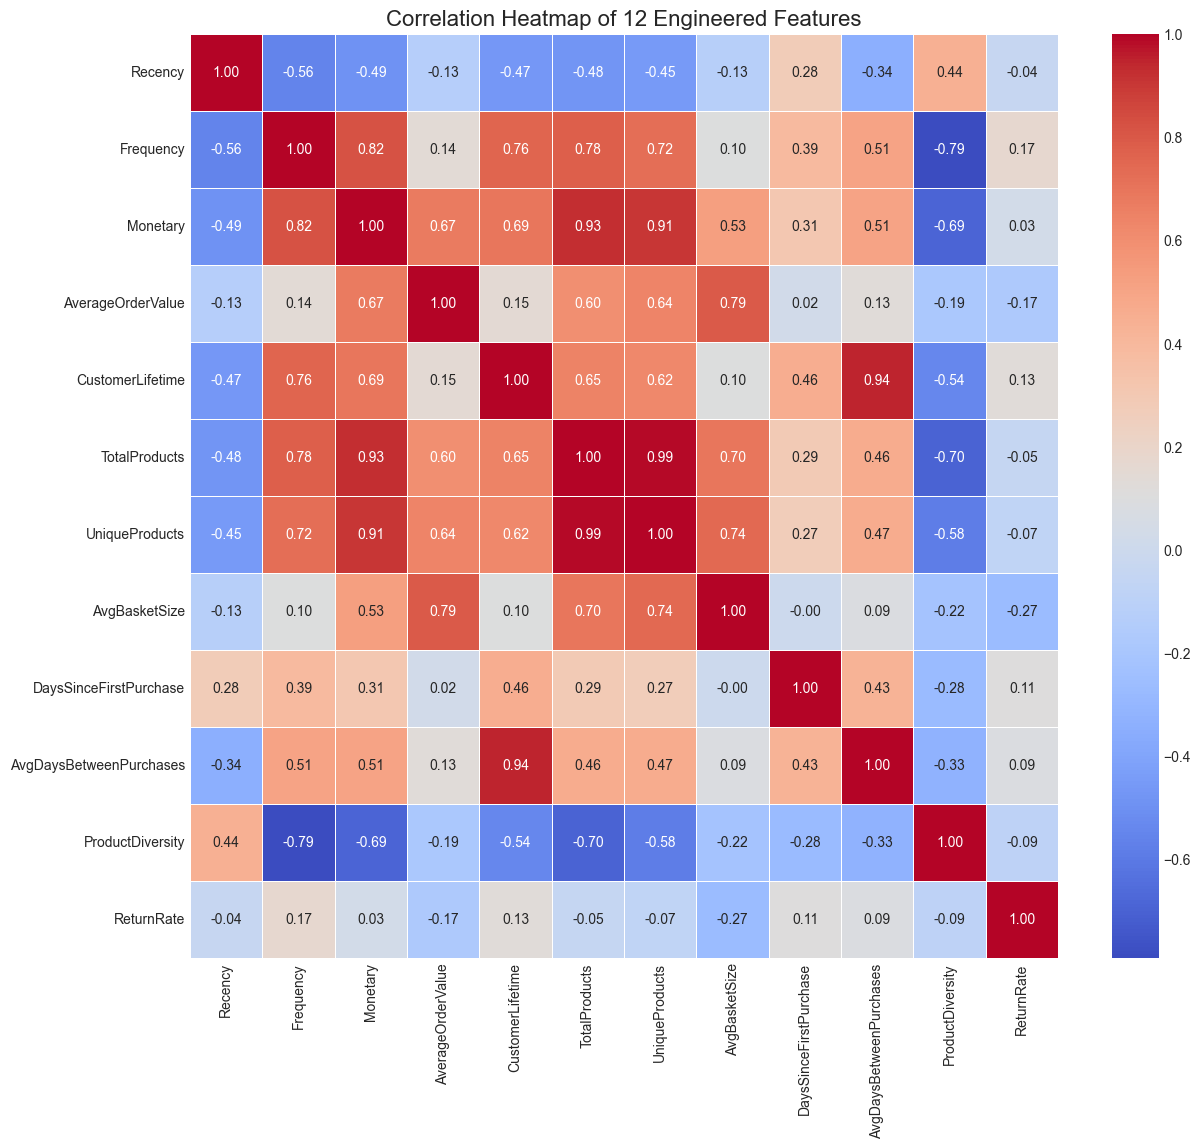

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

# 'scaled_df' is the final DataFrame from your scaling step
# Create a correlation matrix of the scaled data
corr_matrix = scaled_df.corr()

# Plot the heatmap
plt.figure(figsize=(14, 12))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Heatmap of 12 Engineered Features', fontsize=16)
plt.show()

In [19]:
# --- Feature Selection based on Correlation Analysis ---
# 'scaled_df' is your dataframe with all 12 scaled features

# Define the list of features to keep for the model
selected_features = [
    'Recency',
    'Frequency',
    'Monetary',
    'CustomerLifetime',
    'ProductDiversity',
    'ReturnRate'
]

# Create the new dataframe with only the selected features
scaled_df_selected = scaled_df[selected_features]

print("--- Final Selected and Scaled Data for Modeling ---")
print(scaled_df_selected.head())

# --- Re-run the Train-Test Split on the selected data ---
# This updates train_df and test_df to have only the 6 selected features
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(scaled_df_selected, test_size=0.2, random_state=42)

print(f"\nFinal training data shape: {train_df.shape}")
print(f"Final testing data shape: {test_df.shape}")

--- Final Selected and Scaled Data for Modeling ---
              Recency  Frequency  Monetary  CustomerLifetime  \
Customer ID                                                    
12346        1.159706   1.121454 -0.434457          0.479208   
12608        0.987759  -1.058772 -1.354459         -1.482531   
12745        1.106442  -0.540217 -0.355843          0.179977   
12746        1.174151  -1.058772 -0.622988         -1.482531   
12747       -2.178462   2.269844  1.393849          0.966082   

             ProductDiversity  ReturnRate  
Customer ID                                
12346               -0.093547    4.283596  
12608                0.884725   -0.502191  
12745                0.588054   -0.502191  
12746                0.884725    1.098765  
12747               -2.704054    0.247631  

Final training data shape: (4104, 6)
Final testing data shape: (1027, 6)


--- Generating Data Distribution Plots ---


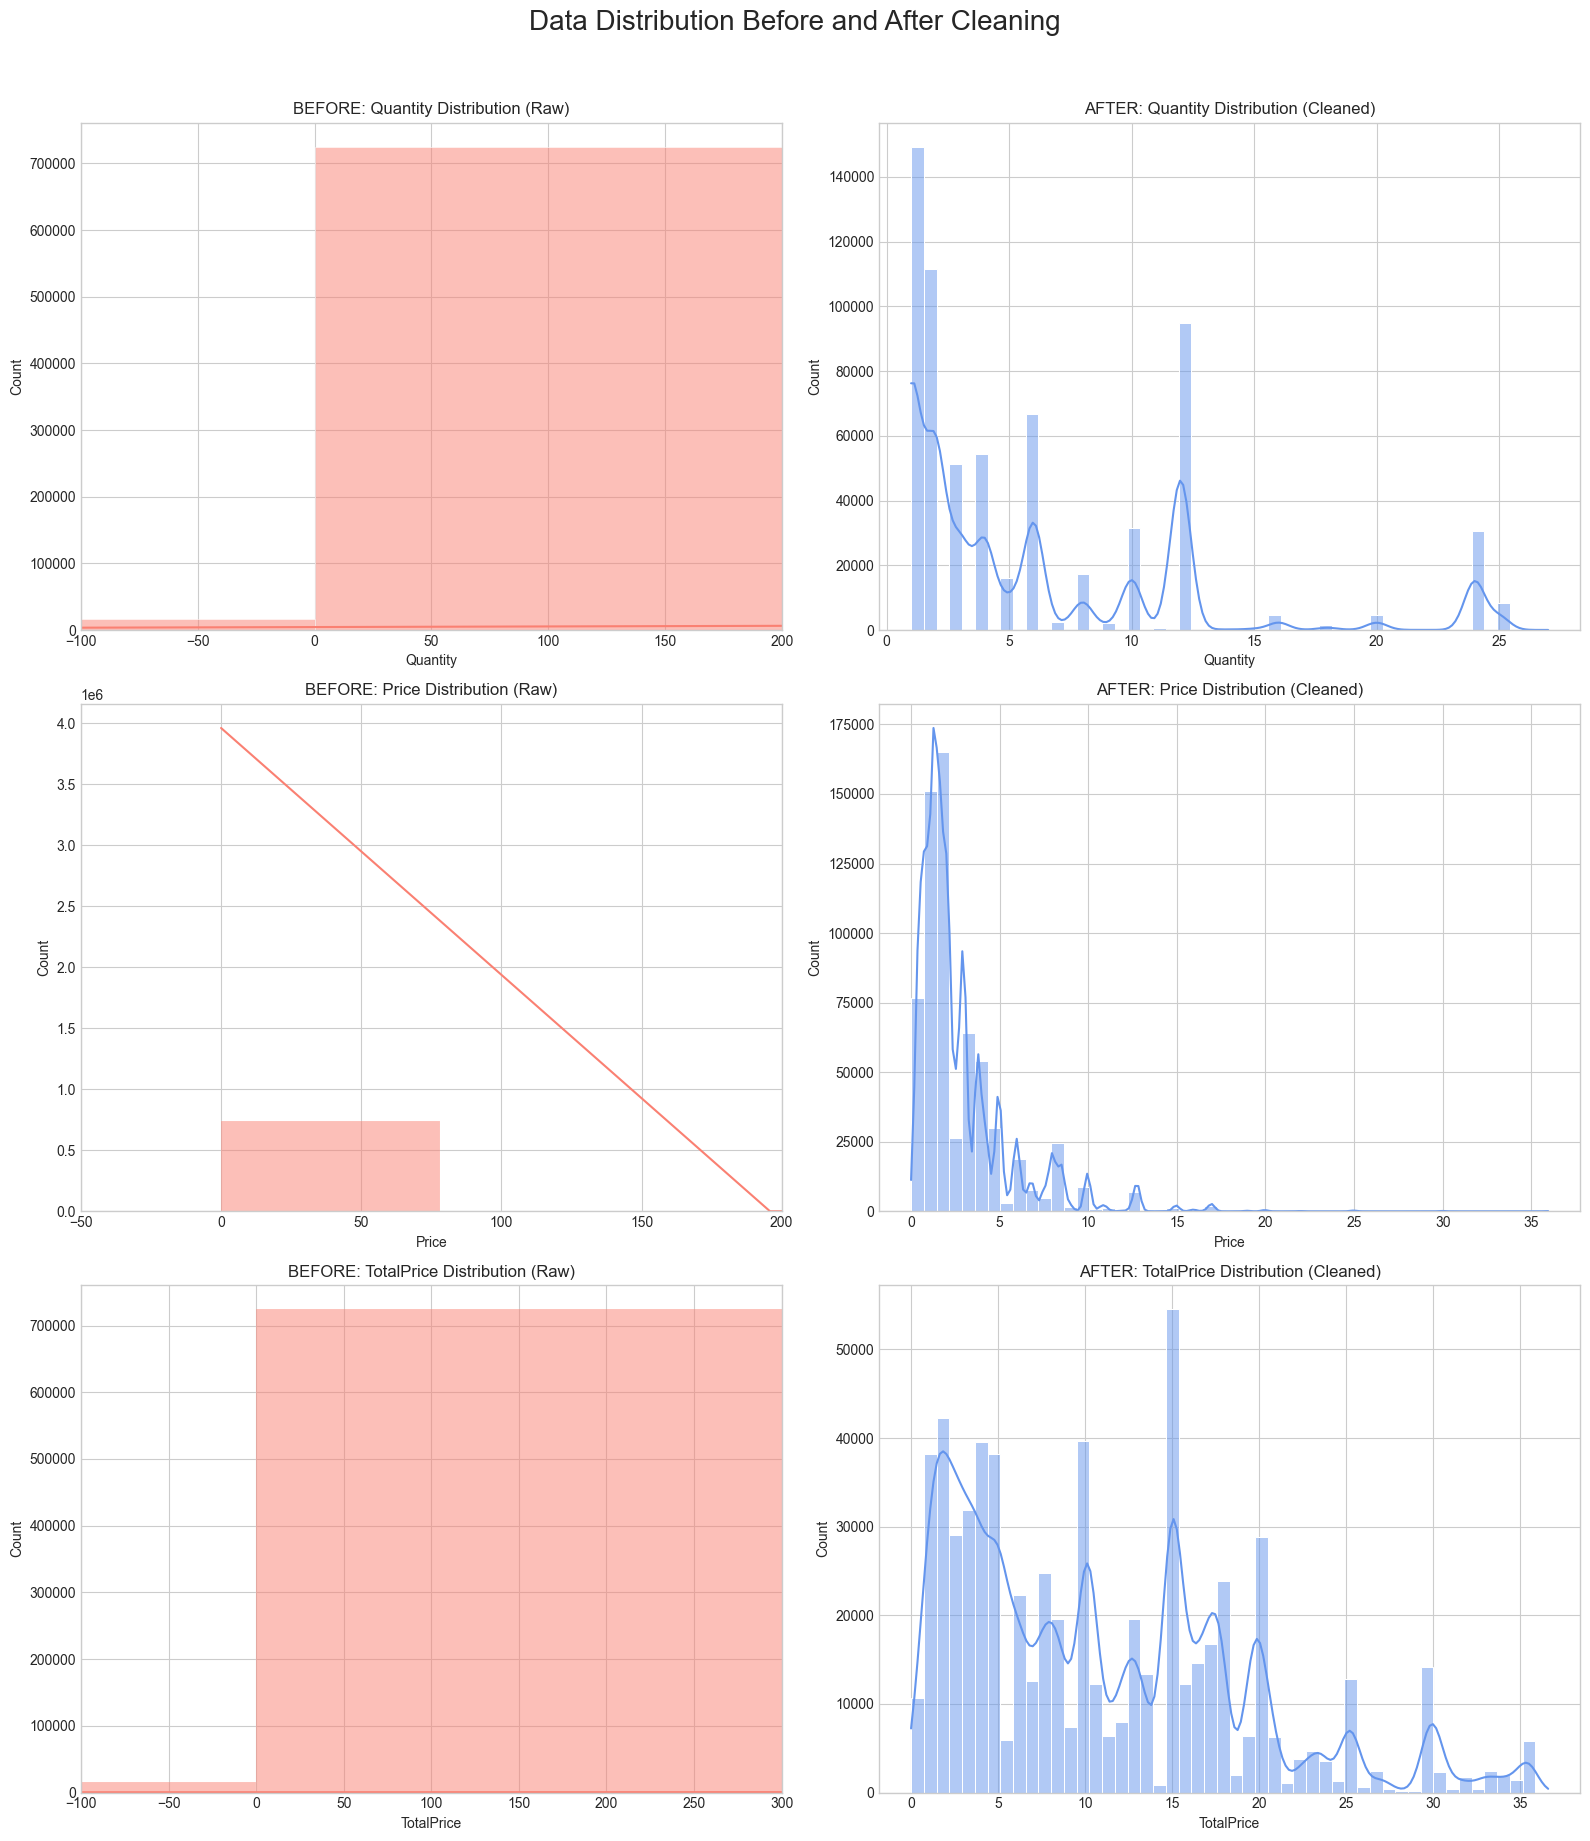


--- Generating Final 'Bell Graphs' (Log-Transformed & Scaled) ---


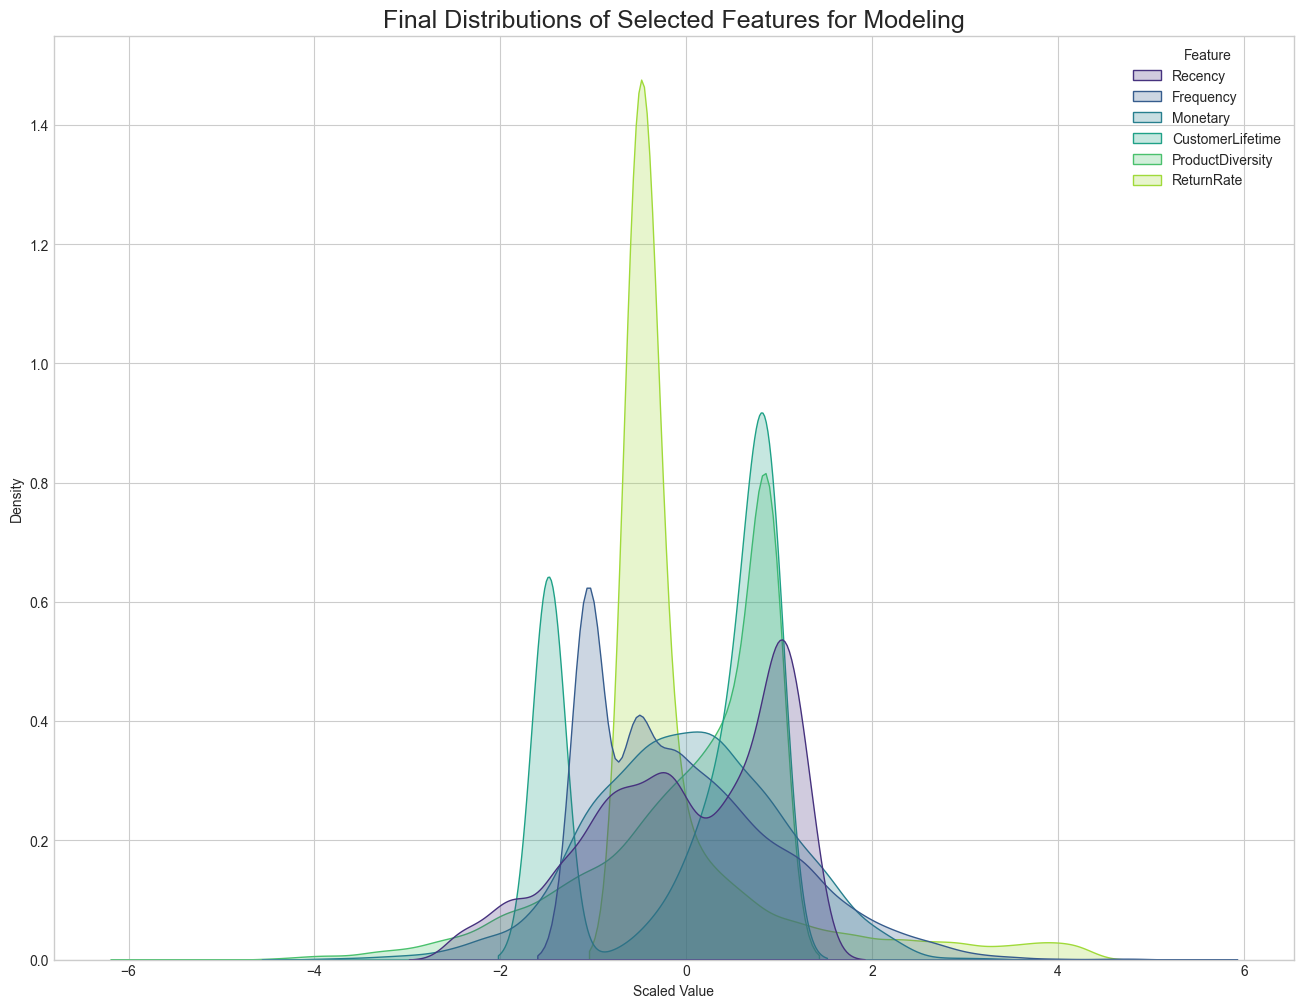

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

print("--- Generating Data Distribution Plots ---")

# --- Create the 3x2 plot grid ---
fig, axes = plt.subplots(3, 2, figsize=(16, 18))
fig.suptitle('Data Distribution Before and After Cleaning', fontsize=20, y=1.02)
sns.set_style("whitegrid")

# --- 1. Quantity ---
# Before (Raw)
sns.histplot(df_uk_before_cleaning['Quantity'], bins=100, kde=True, ax=axes[0, 0], color='salmon')
axes[0, 0].set_title('BEFORE: Quantity Distribution (Raw)')
axes[0, 0].set_xlabel('Quantity')
axes[0, 0].set_xlim(-100, 200) # Zoom in on the main distribution

# After (Cleaned)
sns.histplot(df_uk['Quantity'], bins=50, kde=True, ax=axes[0, 1], color='cornflowerblue')
axes[0, 1].set_title('AFTER: Quantity Distribution (Cleaned)')
axes[0, 1].set_xlabel('Quantity')
# Note: The x-axis is now much smaller due to outlier removal


# --- 2. Price ---
# Before (Raw)
sns.histplot(df_uk_before_cleaning['Price'], bins=500, kde=True, ax=axes[1, 0], color='salmon')
axes[1, 0].set_title('BEFORE: Price Distribution (Raw)')
axes[1, 0].set_xlabel('Price')
axes[1, 0].set_xlim(-50, 200) # Zoom in

# After (Cleaned)
sns.histplot(df_uk['Price'], bins=50, kde=True, ax=axes[1, 1], color='cornflowerblue')
axes[1, 1].set_title('AFTER: Price Distribution (Cleaned)')
axes[1, 1].set_xlabel('Price')


# --- 3. TotalPrice ---
# Before (Raw)
sns.histplot(df_uk_before_cleaning['TotalPrice'], bins=500, kde=True, ax=axes[2, 0], color='salmon')
axes[2, 0].set_title('BEFORE: TotalPrice Distribution (Raw)')
axes[2, 0].set_xlabel('TotalPrice')
axes[2, 0].set_xlim(-100, 300) # Zoom in

# After (Cleaned)
sns.histplot(df_uk['TotalPrice'], bins=50, kde=True, ax=axes[2, 1], color='cornflowerblue')
axes[2, 1].set_title('AFTER: TotalPrice Distribution (Cleaned)')
axes[2, 1].set_xlabel('TotalPrice')


plt.tight_layout()
plt.show()


# --- Generate the "Bell Graph" ---
# This plot shows the final, scaled distribution of your 6 selected features
# 'scaled_df_selected' is your final dataframe from the end of your notebook

print("\n--- Generating Final 'Bell Graphs' (Log-Transformed & Scaled) ---")
plt.figure(figsize=(16, 12))
plt.title('Final Distributions of Selected Features for Modeling', fontsize=18)

# Melt the dataframe to long format for plotting with sns.kdeplot
melted_df = scaled_df_selected.melt(var_name='Feature', value_name='Scaled Value')

sns.kdeplot(data=melted_df, x='Scaled Value', hue='Feature', fill=True, common_norm=False, palette='viridis')
plt.xlabel('Scaled Value')
plt.ylabel('Density')
plt.grid(True)
plt.show()